In [25]:
import sys, importlib
sys.path.append("..")

import bbo_utils
importlib.reload(bbo_utils)

#now using bbo_utils to store all my reusable functions
from bbo_utils import *

functions = load_functions()

In [2]:
for i in range(1, 9):
    check_result(i, functions)
    print()

Function 1
Latest: X=[0.75 0.6 ], y=1.8450686723112454e-12
Best:   X=[0.75 0.6 ], y=1.8450686723112454e-12

Function 2
Latest: X=[0.742475 0.177258], y=0.368468164684646
Best:   X=[0.702637 1.      ], y=0.6710529877291967

Function 3
Latest: X=[0.433348 0.528625 0.418951], y=-0.014403518406881257
Best:   X=[0.4255   0.527545 0.422063], y=-0.010242618647230691

Function 4
Latest: X=[0.41 0.44 0.43 0.44], y=0.19927951093333407
Best:   X=[0.43 0.44 0.43 0.42], y=0.34001099086265585

Function 5
Latest: X=[0.005633 0.985666 0.980462 0.996151], y=3944.0708537614914
Best:   X=[0.005633 0.985666 0.980462 0.996151], y=3944.0708537614914

Function 6
Latest: X=[0.437161 0.320742 0.578847 0.762968 0.194246], y=-0.2489550364199761
Best:   X=[0.45433  0.363869 0.508315 0.757164 0.150167], y=-0.2049823948689158

Function 7
Latest: X=[0.154047 0.257312 0.219209 0.266136 0.307656 0.729736], y=2.688767533788612
Best:   X=[0.154047 0.257312 0.219209 0.266136 0.307656 0.729736], y=2.688767533788612

Funct

### Function 1

In [3]:
check_result(1, functions)

Function 1
Latest: X=[0.75 0.6 ], y=1.8450686723112454e-12
Best:   X=[0.75 0.6 ], y=1.8450686723112454e-12


[0.66666667 0.8        0.93333333 0.53333333 0.         0.4
 0.53333333 0.86666667 0.6        0.73333333 0.26666667 0.13333333
 0.06666667 0.2        0.33333333 1.        ]


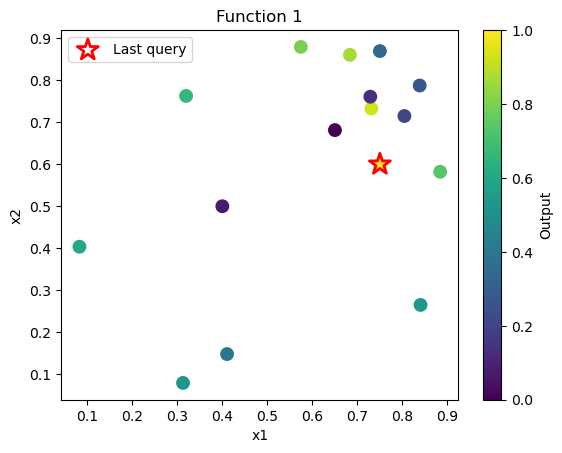

In [4]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, functions, y_scaled)

I am going to be very careful when choosing my next query, as this function seems to be extremely sensitive to small changes. I achieved a very strong result in the previous round, so I now want to focus on exploiting the area around this new best.

#### chosen query for F1

`0.740000-0.610000`

### Function 2

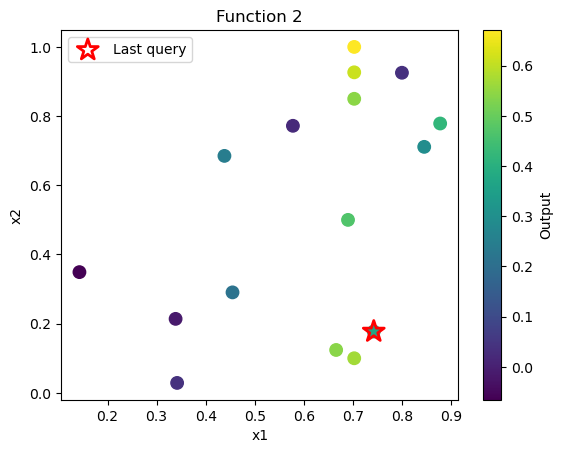

In [5]:
plot_2d(2, functions)

In [6]:
f2_kernel_results = validate_kernels(2, functions)
f2_kernel_results

[(('Matern', 0.1), np.float64(0.17901252279926738)),
 (('RQ', 0.05), np.float64(0.18150286458119297)),
 (('RBF', 0.1), np.float64(0.18212139262425975)),
 (('RQ', 0.1), np.float64(0.18255465260442094)),
 (('RBF', 0.05), np.float64(0.18558555579611186)),
 (('Matern', 0.05), np.float64(0.19175044209151923)),
 (('Matern', 0.2), np.float64(0.2220572366652266)),
 (('RQ', 0.2), np.float64(0.2395948112421234)),
 (('Matern', 0.5), np.float64(0.34664989773334876)),
 (('RBF', 0.2), np.float64(0.4171196925307201)),
 (('RQ', 0.5), np.float64(0.66078719311937)),
 (('RBF', 0.5), np.float64(1.1291935417321721))]

In [7]:
kernel_f2 = Matern(length_scale=0.1)

gp_f2 = fit_gp(2, functions, kernel_f2)

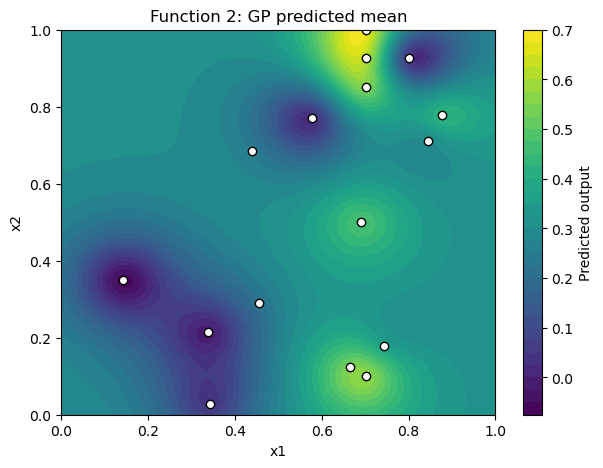

In [8]:
plot_gp_2d(2, gp_f2, functions)

In [9]:
X_candidates = np.array([
    [0.662637, 1.0],
    [0.672637, 1.0],
    [0.682637, 1.0],
    [0.692637, 1.0],
    [0.702637, 1.0],  # Existing observation
    [0.712637, 1.0],
    [0.722637, 1.0],
    [0.732637, 1.0],
    [0.742637, 1.0]
])

mu, sigma = gp_f2.predict(
    X_candidates,
    return_std=True
)

pd.DataFrame({
    "x1": X_candidates[:, 0],
    "x2": X_candidates[:, 1],
    "Predicted Score": mu,
    "Uncertainty": sigma,
    "UCB": mu + 2 * sigma
})

suggestions_f2 = acquisitions(
    gp_f2,
    X_candidates,
    best_y=functions[2]["y"].max()
)

suggestions_f2

{'UCB': array([0.662637, 1.      ]),
 'EI': array([0.662637, 1.      ]),
 'PI': array([0.692637, 1.      ])}

In [10]:
check_uncertainty(gp_f2, suggestions_f2)

UCB: mean=0.6662, uncertainty=0.1252
EI: mean=0.6662, uncertainty=0.1252
PI: mean=0.6851, uncertainty=0.0382


Want to explore candidates with fixed x2 = 0.1 to see if the horizontal region is promising.


#### chosen query for f2

`0.692637, 1.00000`

### Function 3

In [11]:
check_result(3, functions)

Function 3
Latest: X=[0.433348 0.528625 0.418951], y=-0.014403518406881257
Best:   X=[0.4255   0.527545 0.422063], y=-0.010242618647230691


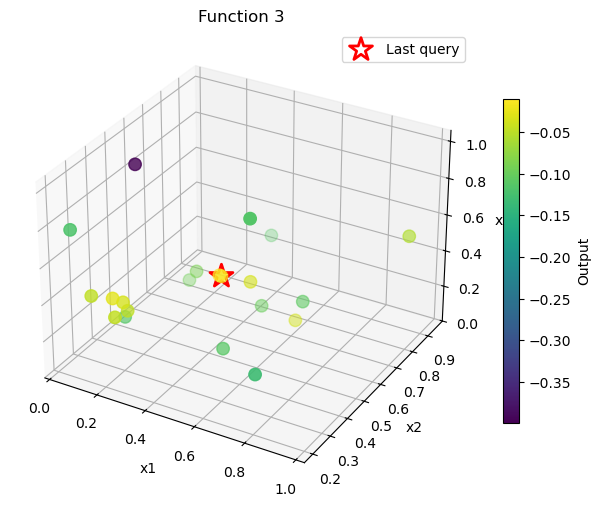

In [12]:
plot_3d(3, functions)

Comparing four GP configurations using leave-one-out validation. I want to establish whether changing the kernel, length scales or noise actually improves F3.

In [26]:
X = functions[3]["X"]
y = functions[3]["y"].ravel()

models = {
    "Current GP": GaussianProcessRegressor(
        kernel=RationalQuadratic(alpha=1, length_scale=0.1),
        alpha=1e-10,
        normalize_y=True,
        optimizer=None
    ),

    "Rational Quadratic + Noise": GaussianProcessRegressor(
        kernel=RationalQuadratic(alpha=1, length_scale=0.1),
        alpha=0.01,
        normalize_y=True,
        optimizer=None
    ),

    "Matern + ARD": GaussianProcessRegressor(
        kernel=Matern(
            length_scale=[0.1, 0.1, 0.1],
            nu=2.5
        ),
        alpha=1e-10,
        normalize_y=True,
        n_restarts_optimizer=5,
        random_state=42
    ),

    "Matern + ARD + Noise": GaussianProcessRegressor(
        kernel=Matern(
            length_scale=[0.1, 0.1, 0.1],
            nu=2.5
        ),
        alpha=0.01,
        normalize_y=True,
        n_restarts_optimizer=5,
        random_state=42
    )
}

In [27]:
results = []

for name, model in models.items():

    predictions = cross_val_predict(
        model, X, y,
        cv=LeaveOneOut()
    )

    rmse = np.sqrt(mean_squared_error(y, predictions))
    mae = np.mean(np.abs(y - predictions))

    model.fit(X, y)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "Fitted Kernel": str(model.kernel_)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


,Model,RMSE,MAE,Fitted Kernel
1,Rational Quadratic + Noise,0.074233,0.034817,"RationalQuadratic(alpha=1, length_scale=0.1)"
0,Current GP,0.074620,0.035917,"RationalQuadratic(alpha=1, length_scale=0.1)"
2,Matern + ARD,0.083356,0.042543,"Matern(length_scale=[7.59, 1.03, 0.0568], nu=2.5)"
3,Matern + ARD + Noise,0.083745,0.041502,"Matern(length_scale=[1.31e+04, 2.94, 0.0623], ..."


In [29]:
for name, model in models.items():

    suggestions = acquisitions(
        model,
        X_candidates,
        best_y=y.max()
    )

    print(f"\n{name}")
    print(suggestions)

    check_uncertainty(model, suggestions)


Current GP
{'UCB': array([0.38599178, 0.62419518, 0.48038515]), 'EI': array([0.36306327, 0.57135762, 0.41942131]), 'PI': array([0.40742953, 0.51978476, 0.4229757 ])}
UCB: mean=-0.0389, uncertainty=0.0616
EI: mean=-0.0130, uncertainty=0.0416
PI: mean=-0.0040, uncertainty=0.0074

Rational Quadratic + Noise
{'UCB': array([0.43341827, 0.63933554, 0.49653345]), 'EI': array([0.40617201, 0.60617731, 0.43884781]), 'PI': array([0.41581857, 0.54858842, 0.40273948])}
UCB: mean=-0.0532, uncertainty=0.0660
EI: mean=-0.0304, uncertainty=0.0507
PI: mean=-0.0132, uncertainty=0.0221

Matern + ARD
{'UCB': array([3.36175580e-01, 9.88036920e-01, 4.63961122e-04]), 'EI': array([0.10162266, 0.94654212, 0.44669989]), 'PI': array([0.37359691, 0.53148521, 0.42581221])}
UCB: mean=-0.0594, uncertainty=0.0712
EI: mean=-0.0003, uncertainty=0.0358
PI: mean=-0.0052, uncertainty=0.0012

Matern + ARD + Noise
{'UCB': array([5.48339883e-01, 4.15367665e-02, 1.07995490e-04]), 'EI': array([0.95088692, 0.99997503, 0.4232394

Adding noise only improves my RMSE by 0.52%.

there is a lot of agreement about keeping x3 in 0.42 region, and x1 and x2 a lot of disagreement since they seem to matter less

decided to choose the PI suggested x3 point from Matérn + ARD + Noise since EI also agreed, then the best performing RQ + noise model's x1 and x2 PI suggestions

#### chosen query for f3

`0.415819-0.548588-0.423239`

### Function 4

In [31]:
check_result(4, functions)

Function 4
Latest: X=[0.41 0.44 0.43 0.44], y=0.19927951093333407
Best:   X=[0.43 0.44 0.43 0.42], y=0.34001099086265585


In [32]:
validate_kernels(4, functions)

[(('RQ', 0.5), np.float64(1.5641922045930468)),
 (('Matern', 0.5), np.float64(1.8295521221598103)),
 (('RQ', 0.2), np.float64(2.6158470404844842)),
 (('RBF', 0.5), np.float64(2.9662790414884443)),
 (('RBF', 0.2), np.float64(3.0386896778811003)),
 (('Matern', 0.2), np.float64(3.094385682131598)),
 (('RQ', 0.1), np.float64(3.402945523522468)),
 (('RBF', 0.1), np.float64(4.121625360196134)),
 (('Matern', 0.1), np.float64(4.245123572895323)),
 (('RQ', 0.05), np.float64(4.5114905222887245)),
 (('RBF', 0.05), np.float64(5.3437058221828675)),
 (('Matern', 0.05), np.float64(5.390157420202551))]

In [33]:
best_kernel_f4 = RationalQuadratic(length_scale=0.5)
gp_f4 = fit_gp(4, functions, best_kernel_f4)

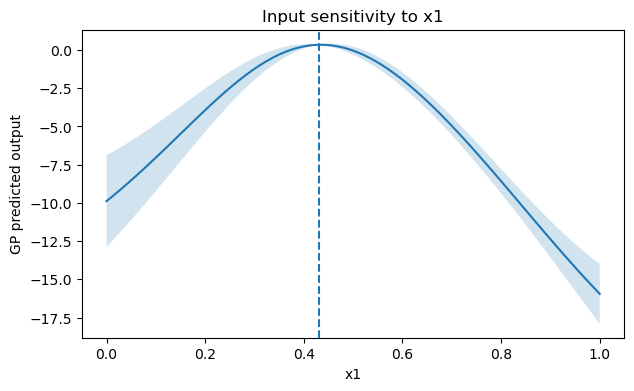

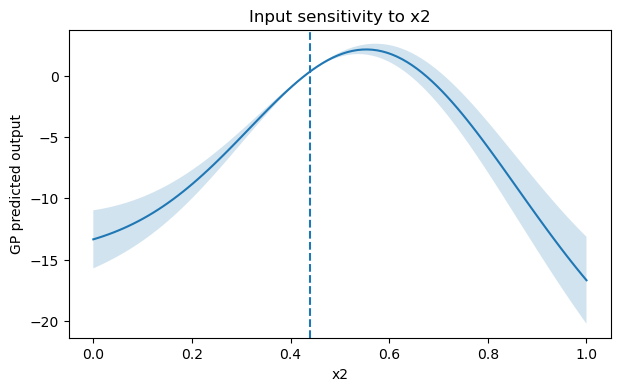

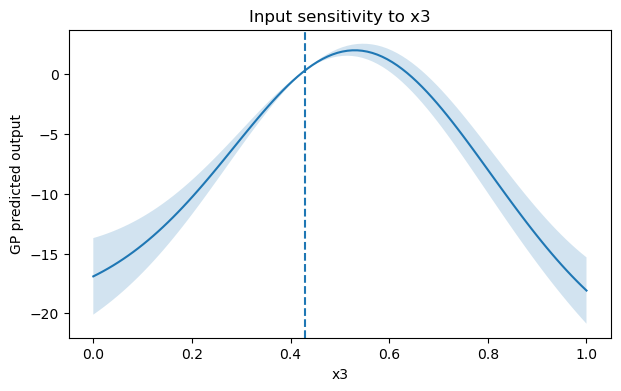

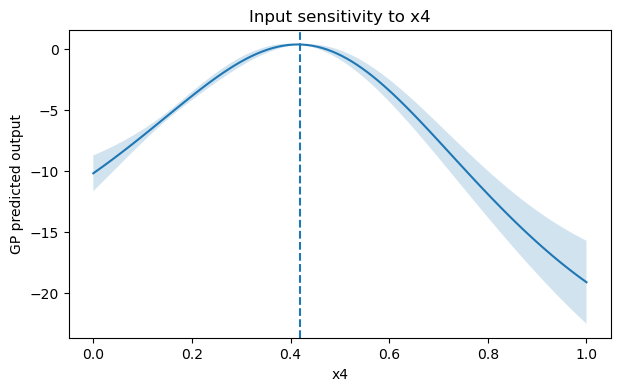

In [34]:
best_idx = np.argmax(functions[4]["y"])
best_x_f4 = functions[4]["X"][best_idx]

plot_input_sensitivity(gp_f4, best_x_f4)

In [38]:
# candidates around the F4 best - this time holding x1 and x4 and moving x2 and x3 up

X_candidates = np.array([
    [0.43, 0.44, 0.43, 0.42],  # current best
    [0.43, 0.45, 0.44, 0.42],
    [0.43, 0.46, 0.45, 0.42],
    [0.43, 0.47, 0.46, 0.42],
])

mean, std = gp_f4.predict(X_candidates, return_std=True)

for point, m, s in zip(X_candidates, mean, std):
    print(
        f"{point} -> "
        f"mean={m:.4f}, uncertainty={s:.4f}"
    )

[0.43 0.44 0.43 0.42] -> mean=0.3400, uncertainty=0.0001
[0.43 0.45 0.44 0.42] -> mean=0.9292, uncertainty=0.0594
[0.43 0.46 0.45 0.42] -> mean=1.4665, uncertainty=0.1206
[0.43 0.47 0.46 0.42] -> mean=1.9466, uncertainty=0.1842


In [39]:
query_f4 = np.array([0.43,0.46,0.45,0.42])

format_query(query_f4)

'0.430000-0.460000-0.450000-0.420000'

#### chosen query for f4

`0.430000-0.460000-0.450000-0.420000`

### Function 5

Function 5
Latest: X=[0.005633 0.985666 0.980462 0.996151], y=3944.0708537614914
Best:   X=[0.005633 0.985666 0.980462 0.996151], y=3944.0708537614914


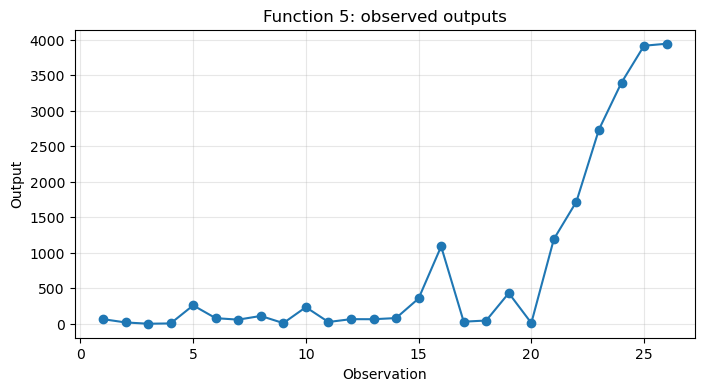

[(('RQ', 0.5), np.float64(70.82020407737029)),
 (('Matern', 0.5), np.float64(76.67254516504502)),
 (('RBF', 0.5), np.float64(131.16246151917017)),
 (('RQ', 0.2), np.float64(143.41334908848515)),
 (('Matern', 0.2), np.float64(303.4928193977631)),
 (('RBF', 0.2), np.float64(305.4889222687768)),
 (('RQ', 0.1), np.float64(345.8199498569496)),
 (('RBF', 0.1), np.float64(570.1191698545786)),
 (('Matern', 0.1), np.float64(586.384699573297)),
 (('RQ', 0.05), np.float64(598.264630618233)),
 (('RBF', 0.05), np.float64(777.9415748803501)),
 (('Matern', 0.05), np.float64(795.4179811442518))]

In [40]:
check_result(5, functions)
plot_scores(5, functions)

validate_kernels(5, functions)

The broad pattern has been pretty clear: x1 ↓, while x2/x3/x4 move towards 1.

And unlike F4, following that direction has repeatedly produced improvements. So I think we can afford to be more aggressive with F5.

In fact, we're basically at the boundaries already. The obvious aggressive candidate I'd want to investigate is: [0.0, 1.0, 1.0, 1.0] which is already pretty close to my current best point. 

I will put this aggressive point alongside other less extreme candidates through the GP before deciding.

In [47]:
kernel_f5 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f5 = fit_gp(5, functions, kernel_f5)

In [48]:
current_best_f5 = np.array([
    0.005633, 0.985666, 0.980462, 0.996151
])

boundary_f5 = np.array([
    0.0, 1.0, 1.0, 1.0
])

X_candidates = np.array([
    current_best_f5,
    current_best_f5 + 0.25 * (boundary_f5 - current_best_f5),
    current_best_f5 + 0.50 * (boundary_f5 - current_best_f5),
    current_best_f5 + 0.75 * (boundary_f5 - current_best_f5),
    boundary_f5
])

X_candidates

array([[0.005633  , 0.985666  , 0.980462  , 0.996151  ],
       [0.00422475, 0.9892495 , 0.9853465 , 0.99711325],
       [0.0028165 , 0.992833  , 0.990231  , 0.9980755 ],
       [0.00140825, 0.9964165 , 0.9951155 , 0.99903775],
       [0.        , 1.        , 1.        , 1.        ]])

In [51]:
mean, std = gp_f5.predict(
    X_candidates,
    return_std=True
)

for point, m, s in zip(X_candidates, mean, std):
    print(
        f"{point} -> "
        f"mean={m:.2f}, uncertainty={s:.2f}"
    )

[0.005633 0.985666 0.980462 0.996151] -> mean=3944.07, uncertainty=0.01
[0.00422475 0.9892495  0.9853465  0.99711325] -> mean=4006.30, uncertainty=8.89
[0.0028165 0.992833  0.990231  0.9980755] -> mean=4067.63, uncertainty=17.98
[0.00140825 0.9964165  0.9951155  0.99903775] -> mean=4128.01, uncertainty=27.26
[0. 1. 1. 1.] -> mean=4187.37, uncertainty=36.72


F5 has shown a consistent direction of improvement across several rounds. Hence I tested increasingly larger steps towards the boundary [0, 1, 1, 1], and the GP is predicting a steady increase in score at each step. So, I want to make a larger move and fully exploit this promising direction.

#### chosen query for f5

`0.000000-1.000000-1.000000-1.000000`

### Function 6

Function 6
Latest: X=[0.437161 0.320742 0.578847 0.762968 0.194246], y=-0.2489550364199761
Best:   X=[0.45433  0.363869 0.508315 0.757164 0.150167], y=-0.2049823948689158


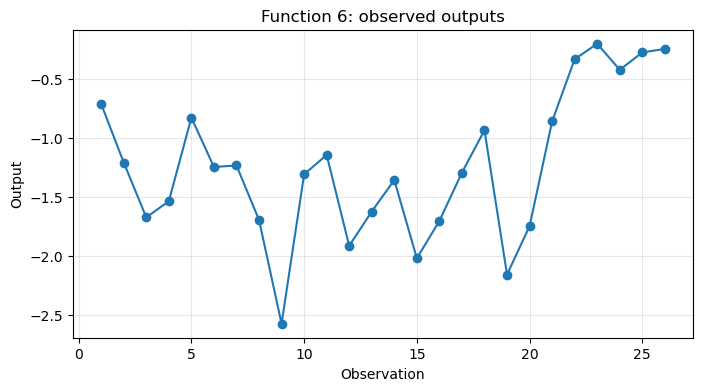

In [61]:
check_result(6, functions)
plot_scores(6, functions)

In [70]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, cross_val_score

X = functions[6]["X"]
y = functions[6]["y"]

svr_models = {
    "RBF C=1": SVR(kernel="rbf", C=1),
    "RBF C=10": SVR(kernel="rbf", C=10),
    "RBF C=100": SVR(kernel="rbf", C=100),
}

for name, svr in svr_models.items():

    model = make_pipeline(
        StandardScaler(),
        svr
    )

    mae = -cross_val_score(
        model,
        X,
        y,
        cv=LeaveOneOut(),
        scoring="neg_mean_absolute_error"
    ).mean()

    print(f"{name}: MAE={mae:.4f}")

RBF C=1: MAE=0.1587
RBF C=10: MAE=0.1525
RBF C=100: MAE=0.1525


In [63]:
svr_f6 = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10)
)

svr_f6.fit(
    functions[6]["X"],
    functions[6]["y"]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](5,)","[0.53,0.5 ,0.49,0.59,0.36]"


In [64]:
best_x_f6 = np.array([
    0.454330, 0.363869, 0.508315, 0.757164, 0.150167
])

best_y_f6 = -0.2049823948689158

In [65]:
np.random.seed(42)

n_candidates = 20000

X_candidates = best_x_f6 + np.random.normal(
    loc=0,
    scale=0.08,
    size=(n_candidates, 5)
)

X_candidates = np.clip(X_candidates, 0, 1)

In [66]:
validate_kernels(6, functions)

[(('RQ', 0.2), np.float64(0.23443279583595725)),
 (('Matern', 0.5), np.float64(0.2473240742707895)),
 (('RQ', 0.5), np.float64(0.2520844746566244)),
 (('Matern', 0.2), np.float64(0.28490762324040053)),
 (('RBF', 0.2), np.float64(0.29778335121464705)),
 (('RQ', 0.1), np.float64(0.30262484193863626)),
 (('RBF', 0.1), np.float64(0.36275219273805287)),
 (('Matern', 0.1), np.float64(0.36829155502859806)),
 (('RQ', 0.05), np.float64(0.3779000044154889)),
 (('RBF', 0.5), np.float64(0.39379522587863386)),
 (('RBF', 0.05), np.float64(0.4351209364969867)),
 (('Matern', 0.05), np.float64(0.4354281341094477))]

In [67]:
gp_f6 = fit_gp(
    6,
    functions,
    RationalQuadratic(length_scale=0.2, alpha=1.0)
)

In [71]:
# SVR gives us the predicted mean
svr_mean = svr_f6.predict(X_candidates)

svr_scaled = (
    (svr_mean - svr_mean.min()) /
    (svr_mean.max() - svr_mean.min())
)

uncertainty_scaled = (
    (gp_std - gp_std.min()) /
    (gp_std.max() - gp_std.min())
)

In [72]:
hybrid_score = (
    0.75 * svr_scaled +
    0.25 * uncertainty_scaled
)

top_idx = np.argsort(hybrid_score)[-10:][::-1]

for idx in top_idx:
    print(
        X_candidates[idx],
        f"SVR={svr_mean[idx]:.4f}",
        f"GP uncertainty={gp_std[idx]:.4f}",
        f"Hybrid={hybrid_score[idx]:.4f}"
    )

[0.42672178 0.4499723  0.57342083 0.77945351 0.0660256 ] SVR=-0.3465 GP uncertainty=0.3569 Hybrid=0.8520
[0.39889344 0.445956   0.5758182  0.78245103 0.09652355] SVR=-0.3428 GP uncertainty=0.3467 Hybrid=0.8518
[0.42108315 0.42290873 0.59936835 0.79037589 0.10660478] SVR=-0.3351 GP uncertainty=0.3256 Hybrid=0.8513
[0.42393736 0.40829937 0.57712181 0.7875328  0.08327203] SVR=-0.3261 GP uncertainty=0.3015 Hybrid=0.8509
[0.39794467 0.44565265 0.60157584 0.76239843 0.09581081] SVR=-0.3514 GP uncertainty=0.3665 Hybrid=0.8505
[0.44923072 0.38888413 0.59177803 0.79921196 0.06624498] SVR=-0.3360 GP uncertainty=0.3246 Hybrid=0.8496
[0.47310838 0.42015048 0.59353823 0.80654428 0.07873423] SVR=-0.3439 GP uncertainty=0.3442 Hybrid=0.8491
[0.43793305 0.40760925 0.60549924 0.80213934 0.10127644] SVR=-0.3360 GP uncertainty=0.3227 Hybrid=0.8487
[0.46115534 0.39023867 0.60783322 0.7997236  0.07148648] SVR=-0.3423 GP uncertainty=0.3390 Hybrid=0.8487
[0.46638075 0.44472899 0.58528163 0.79880934 0.07023531

In [73]:
hybrid_score = (
    0.90 * svr_scaled +
    0.10 * uncertainty_scaled
)

top_idx = np.argsort(hybrid_score)[-10:][::-1]

for idx in top_idx:
    print(
        X_candidates[idx],
        f"SVR={svr_mean[idx]:.4f}",
        f"GP uncertainty={gp_std[idx]:.4f}",
        f"Hybrid={hybrid_score[idx]:.4f}"
    )

[0.44443449 0.39186353 0.55699481 0.75997681 0.10527756] SVR=-0.3053 GP uncertainty=0.2011 Hybrid=0.9273
[0.44909133 0.40220609 0.56111116 0.75072224 0.1032089 ] SVR=-0.3084 GP uncertainty=0.2177 Hybrid=0.9259
[0.43444387 0.39084811 0.55965928 0.75474389 0.0867554 ] SVR=-0.3109 GP uncertainty=0.2313 Hybrid=0.9247
[0.43174445 0.4052575  0.55312163 0.76050886 0.08708176] SVR=-0.3127 GP uncertainty=0.2442 Hybrid=0.9245
[0.42336727 0.41032931 0.54701444 0.77108366 0.09506808] SVR=-0.3131 GP uncertainty=0.2436 Hybrid=0.9237
[0.42111885 0.40932236 0.57605127 0.75366665 0.11083302] SVR=-0.3157 GP uncertainty=0.2603 Hybrid=0.9230
[0.44205292 0.38875764 0.54558921 0.78447176 0.08617726] SVR=-0.3114 GP uncertainty=0.2264 Hybrid=0.9230
[0.43425927 0.38289763 0.54703341 0.76709669 0.08281713] SVR=-0.3099 GP uncertainty=0.2142 Hybrid=0.9229
[0.4379601  0.39538547 0.55439709 0.7409457  0.08327976] SVR=-0.3123 GP uncertainty=0.2291 Hybrid=0.9222
[0.43120809 0.39658989 0.55295697 0.77634285 0.14271989

The SVR has been better at identifying promising points than accurately predicting their outputs, so I used it as the main ranking model and combined it with GP uncertainty (90:10). This allowed some controlled exploration while keeping the SVR as the main driver of the query choice.

In [74]:
svr_query_f6 = [0.444434, 0.391864, 0.556995, 0.759977, 0.105278]

In [75]:
format_query(svr_query_f6)

'0.444434-0.391864-0.556995-0.759977-0.105278'

#### chosen query for f6

`0.444434-0.391864-0.556995-0.759977-0.105278`

### Function 7

Function 7
Latest: X=[0.154047 0.257312 0.219209 0.266136 0.307656 0.729736], y=2.688767533788612
Best:   X=[0.154047 0.257312 0.219209 0.266136 0.307656 0.729736], y=2.688767533788612


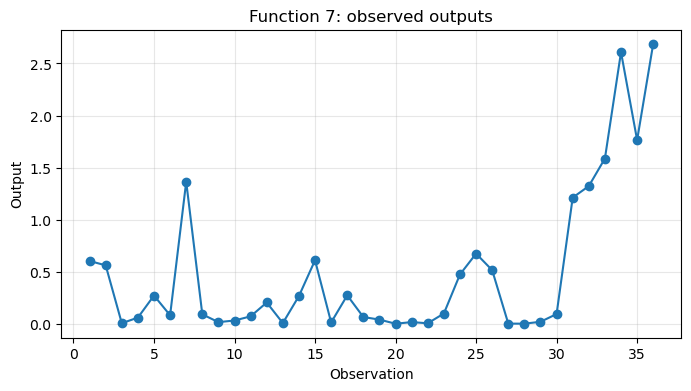

[(('RQ', 0.5), np.float64(0.1971310856743462)),
 (('RQ', 0.2), np.float64(0.19796069984614453)),
 (('Matern', 0.5), np.float64(0.2060700993063469)),
 (('Matern', 0.2), np.float64(0.26833349422086245)),
 (('RBF', 0.2), np.float64(0.2715037107284382)),
 (('RQ', 0.1), np.float64(0.28083518495282983)),
 (('RBF', 0.5), np.float64(0.3266916116389568)),
 (('RBF', 0.1), np.float64(0.3565253125741486)),
 (('Matern', 0.1), np.float64(0.36179354767594674)),
 (('RQ', 0.05), np.float64(0.38316204159926975)),
 (('RBF', 0.05), np.float64(0.4471825895078536)),
 (('Matern', 0.05), np.float64(0.45780038551393204))]

In [76]:
check_result(7, functions)
plot_scores(7, functions)

validate_kernels(7, functions)

In [81]:
kernel_f7 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f7 = fit_gp(7, functions, kernel_f7)

In [82]:
#generating candidates around current best - 0.08 around

np.random.seed(42)

best_x_f7 = functions[7]["X"][np.argmax(functions[7]["y"])]

X_candidates_f7 = best_x_f7 + np.random.normal(
    loc=0,
    scale=0.08,
    size=(100000, 6)
)

X_candidates_f7 = np.clip(X_candidates_f7, 0, 1)

suggestions_f7 = acquisitions(
    gp_f7,
    X_candidates_f7,
    best_y=functions[7]["y"].max()
)

suggestions_f7

{'UCB': array([0.2850308 , 0.20325467, 0.24271195, 0.33427828, 0.32098339,
        0.85574172]),
 'EI': array([0.22744294, 0.21948652, 0.23931003, 0.30834156, 0.33201801,
        0.77961104]),
 'PI': array([0.16890056, 0.25416315, 0.22024452, 0.27107855, 0.31804893,
        0.73455536])}

In [83]:
check_uncertainty(gp_f7, suggestions_f7)

UCB: mean=2.8082, uncertainty=0.2028
EI: mean=2.9012, uncertainty=0.1026
PI: mean=2.7452, uncertainty=0.0167


In [84]:
query_f7 = suggestions_f7["EI"]
format_query(query_f7)

'0.227443-0.219487-0.239310-0.308342-0.332018-0.779611'

#### chosen query for f7

`0.227443-0.219487-0.239310-0.308342-0.332018-0.779611`

### Function 8

Function 8
Latest: X=[0.141618 0.394607 0.109841 0.351962 0.526364 0.530209 0.32156  0.404404], y=9.8229651337654
Best:   X=[0.105481 0.269158 0.077575 0.241274 0.445941 0.627114 0.326085 0.673392], y=9.8579948536101


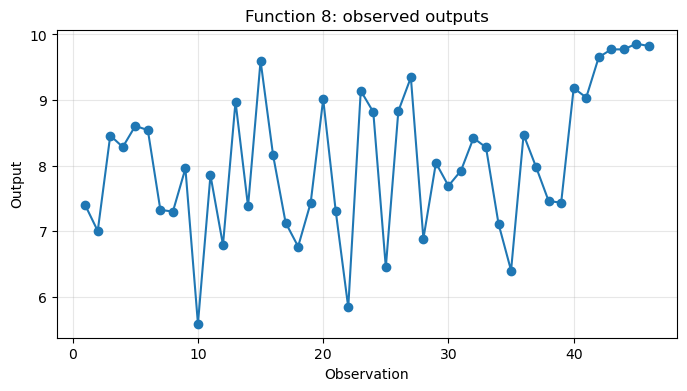

[(('RQ', 0.5), np.float64(0.33005449061342906)),
 (('RBF', 0.5), np.float64(0.3856162584094365)),
 (('Matern', 0.5), np.float64(0.39742030274090145)),
 (('RQ', 0.2), np.float64(0.5287268576885611)),
 (('RQ', 0.1), np.float64(0.6736299683405416)),
 (('Matern', 0.2), np.float64(0.6918299766428092)),
 (('RBF', 0.2), np.float64(0.7015864079915481)),
 (('RQ', 0.05), np.float64(0.7698637156164393)),
 (('RBF', 0.1), np.float64(0.7760223234058384)),
 (('Matern', 0.1), np.float64(0.7801588981325768)),
 (('RBF', 0.05), np.float64(0.8192229132560399)),
 (('Matern', 0.05), np.float64(0.8228532304713803))]

In [85]:
check_result(8, functions)
plot_scores(8, functions)

validate_kernels(8, functions)

In [86]:
kernel_f8 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f8 = fit_gp(8, functions, kernel_f8)

In [90]:
best_x_f8 = np.array([
    0.105481, 0.269158, 0.077575, 0.241274,
    0.445941, 0.627114, 0.326085, 0.673392
])

round6_x_f8 = np.array([
    0.141618, 0.394607, 0.109841, 0.351962,
    0.526364, 0.530209, 0.321560, 0.404404
])

steps = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])

X_candidates = np.array([
    best_x_f8 + step * (round6_x_f8 - best_x_f8)
    for step in steps
])

mean, std = gp_f8.predict(X_candidates, return_std=True)

for step, x, m, s in zip(steps, X_candidates, mean, std):
    print(
        f"{step:.0%} toward R6:",
        x,
        f"mean={m:.4f}",
        f"uncertainty={s:.4f}"
    )

0% toward R6: [0.105481 0.269158 0.077575 0.241274 0.445941 0.627114 0.326085 0.673392] mean=9.8580 uncertainty=0.0000
10% toward R6: [0.1090947 0.2817029 0.0808016 0.2523428 0.4539833 0.6174235 0.3256325
 0.6464932] mean=9.8665 uncertainty=0.0332
20% toward R6: [0.1127084 0.2942478 0.0840282 0.2634116 0.4620256 0.607733  0.32518
 0.6195944] mean=9.8725 uncertainty=0.0616
30% toward R6: [0.1163221 0.3067927 0.0872548 0.2744804 0.4700679 0.5980425 0.3247275
 0.5926956] mean=9.8759 uncertainty=0.0839
40% toward R6: [0.1199358 0.3193376 0.0904814 0.2855492 0.4781102 0.588352  0.324275
 0.5657968] mean=9.8766 uncertainty=0.0986
50% toward R6: [0.1235495 0.3318825 0.093708  0.296618  0.4861525 0.5786615 0.3238225
 0.538898 ] mean=9.8747 uncertainty=0.1048


#### chosen query for f8

`0.119936-0.319338-0.090481-0.285549-0.478110-0.588352-0.324275-0.565797`

I tested smaller incremental steps from the current best towards the Round 6 point to identify where performance was predicted to start declining. The predicted score increased up to the 40% point, but began to decrease at 50%, so I selected 40% as the next query.